# EDA: IDS na danych OT (HAI 21.03)

Projekt ASI, s28129. Celem jest zrozumienie danych przed budową detektora anomalii dla środowiska OT (systemy sterowania procesem przemysłowym).

**Jak czytać ten notebook:** każda nieoczywista decyzja o danych ma blok **Decyzja Dn** z uzasadnieniem i przykładem z danych. Pełna tabela decyzji jest na końcu.

Etapy:
1. Wczytanie danych i znaczenie kolumn
2. Czas i kolejność plików
3. Jakość danych: braki, duplikaty, kolumny stałe
4. Etykiety i ataki
5. Statystyki, histogramy, boxploty, wartości odstające
6. Zmienne kategoryczne
7. Korelacje i kolumny nadmiarowe
8. Pary zmiennych
9. Czy jeden plik treningowy wystarczy?
10. Co dzieje się po zakończeniu ataku
11. Tabela decyzji i dalsze kroki

## 0. Wybór danych

> **Decyzja D1: zbiór HAI 21.03 zamiast CIC-IDS2017**
> Projekt ma dotyczyć środowisk OT, a CIC-IDS2017 to ruch sieciowy z biura (IT). HAI pochodzi ze stanowiska hardware-in-the-loop z prawdziwymi sterownikami PLC. Pliki train zawierają wyłącznie normalną pracę, więc idealnie pasują do detekcji anomalii. Zbiór jest publiczny (CC BY-SA 4.0) i nie wymaga logowania.
> Odrzucone: BATADAL (symulacja, pomiary co godzinę, mało danych), Morris gas pipeline (znane artefakty ułatwiające wykrywanie), HAI 22.04 i 23.05 (większe pliki i dużo trudniejsze ataki).
> **Konsekwencja:** IDS analizuje pomiary procesu, a nie ruch sieciowy. Wykrywa więc skutek ataku w procesie fizycznym.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', font_scale=0.9)

data_dir = '../data/01_raw/'
train = pd.read_csv(data_dir + 'train1.csv.gz')
test1 = pd.read_csv(data_dir + 'test1.csv.gz')
test2 = pd.read_csv(data_dir + 'test2.csv.gz')

for d in (train, test1, test2):
    d['time'] = pd.to_datetime(d['time'])

print(train.shape, test1.shape, test2.shape)
train.head()

(216001, 84) (43201, 84) (118801, 84)


,time,P1_B2004,P1_B2016,P1_B3004,P1_B3005,P1_B4002,P1_B4005,P1_B400B,P1_B4022,P1_FCV01D,P1_FCV01Z,P1_FCV02D,P1_FCV02Z,P1_FCV03D,P1_FCV03Z,P1_FT01,P1_FT01Z,P1_FT02,P1_FT02Z,P1_FT03,...,P3_LH,P3_LIT01,P3_LL,P3_PIT01,P4_HT_FD,P4_HT_LD,P4_HT_PO,P4_HT_PS,P4_LD,P4_ST_FD,P4_ST_GOV,P4_ST_LD,P4_ST_PO,P4_ST_PS,P4_ST_PT01,P4_ST_TT01,attack,attack_P1,attack_P2,attack_P3
0,2020-07-11 00:00:00,0.10121,1.29784,397.63785,1001.99799,33.6555,100.0,2847.02539,37.14706,100.0,100.0,0.0,-1.87531,51.58201,52.80456,166.74039,808.29620,1973.19031,2847.02539,246.43968,...,70,15454.0,20,815.0,-0.00072,0.06511,4.01474,0,301.01636,-0.00297,16495.0,301.35992,305.03113,0,10052.0,27610.0,0,0,0,0
1,2020-07-11 00:00:01,0.10121,1.29692,397.63785,1001.99799,33.6555,100.0,2839.58520,37.14477,100.0,100.0,0.0,-1.88294,51.60648,52.78931,168.64778,819.16809,1975.47900,2839.58520,246.43968,...,70,15461.0,20,883.0,-0.00051,0.04340,3.74347,0,297.43567,0.00072,16402.0,297.43567,304.27161,0,10052.0,27610.0,0,0,0,0
2,2020-07-11 00:00:02,0.10121,1.29631,397.63785,1001.99799,33.6555,100.0,2833.26807,37.14325,100.0,100.0,0.0,-1.88294,51.57790,52.79694,168.83849,823.51697,1972.42725,2833.26807,246.05821,...,70,15462.0,20,956.0,-0.00043,0.04340,3.43603,0,298.84619,-0.00145,16379.0,298.66534,303.89179,0,10050.0,27617.0,0,0,0,0
3,2020-07-11 00:00:03,0.10121,1.28685,397.63785,1001.99799,33.6555,100.0,2834.95264,37.11959,100.0,100.0,0.0,-1.88294,51.58236,52.79694,170.55510,823.95172,1983.10828,2834.95264,246.63045,...,70,15466.0,20,992.0,-0.00072,0.02170,3.12860,0,297.74310,-0.00318,16422.0,298.06860,303.67474,0,10052.0,27614.0,0,0,0,0
4,2020-07-11 00:00:04,0.10121,1.28807,397.63785,1001.99799,33.6555,100.0,2832.70654,37.12265,100.0,100.0,0.0,-1.88294,51.62335,52.79694,171.31805,827.86560,1986.16016,2832.70654,246.24898,...,70,15461.0,20,1074.0,-0.00051,0.02170,2.87546,0,297.01965,0.00015,16355.0,296.53137,303.22266,0,10052.0,27621.0,0,0,0,0


## 1. Znaczenie kolumn

84 kolumny to `time`, 79 punktów pomiarowych i 4 etykiety. README zbioru podaje 78 punktów, a w plikach jest ich 79, więc liczymy to, co faktycznie jest w danych.

| Prefiks | Proces |
|---|---|
| `P1` | kocioł (woda, ciśnienie, temperatura) |
| `P2` | turbina |
| `P3` | uzdatnianie wody |
| `P4` | symulacja HIL (zapotrzebowanie na moc) |

Końcówki nazw według dokumentacji technicznej: `...D` to polecenie położenia zaworu, `...Z` to jego rzeczywiste położenie, `B....` to wartości zadane, `FT` przepływ, `PIT` ciśnienie, `TIT` temperatura, `LIT` poziom, `SIT` obroty.

In [2]:
labels = ['attack', 'attack_P1', 'attack_P2', 'attack_P3']
features = [c for c in train.columns if c not in ['time'] + labels]

print('Punkty pomiarowe:', len(features))
print(pd.Series([c.split('_')[0] for c in features]).value_counts().to_dict())
print('Te same kolumny w plikach:', list(train.columns) == list(test1.columns) == list(test2.columns))
print(train[features].dtypes.value_counts().to_dict())

Punkty pomiarowe: 79
{'P1': 38, 'P2': 22, 'P4': 12, 'P3': 7}
Te same kolumny w plikach: True
{dtype('float64'): 55, dtype('int64'): 24}


## 2. Czas i kolejność plików

In [3]:
def episodes(attack):
    a = np.asarray(attack).astype(int)
    starts = np.where((a == 1) & (np.r_[0, a[:-1]] == 0))[0]
    ends = np.where((a == 1) & (np.r_[a[1:], 0] == 0))[0]
    return list(zip(starts, ends))

files = pd.DataFrame([{
    'plik': name,
    'wiersze': len(d),
    'start': d['time'].min(),
    'koniec': d['time'].max(),
    'krok [s]': d['time'].diff().dt.total_seconds().max(),
    'ataki': len(episodes(d['attack'])),
    'udział ataków': round(d['attack'].mean(), 4),
} for name, d in [('train1', train), ('test1', test1), ('test2', test2)]])
files

,plik,wiersze,start,koniec,krok [s],ataki,udział ataków
0,train1,216001,2020-07-11 00:00:00,2020-07-13 12:00:00,1.0,0,0.0000
1,test1,43201,2020-07-07 15:00:00,2020-07-08 03:00:00,1.0,5,0.0146
2,test2,118801,2020-07-09 15:00:00,2020-07-11 00:00:00,1.0,20,0.0290


In [4]:
continuous_all = [c for c in features if train[c].nunique() > 100]
print('Autokorelacja, mediana po zmiennych ciągłych:')
print('  1 s: ', round(train[continuous_all].apply(lambda s: s.autocorr(1)).median(), 4))
print('  60 s:', round(train[continuous_all].apply(lambda s: s.autocorr(60)).median(), 4))

same_time = test2['time'].iloc[-1] == train['time'].iloc[0]
same_values = (test2[features].iloc[-1].astype(float) == train[features].iloc[0].astype(float)).sum()
print('Koniec test2 = początek train1:', same_time, ', zgodne wartości:', same_values, '/', len(features))

Autokorelacja, mediana po zmiennych ciągłych:


  1 s:  0.9992


  60 s: 0.7988
Koniec test2 = początek train1: True , zgodne wartości: 79 / 79


Pomiary są co sekundę bez żadnych przerw. Dwa fakty mają konsekwencje:
- Plik train jest **późniejszy** niż pliki test: test1 to 7 lipca, test2 to 9–11 lipca, a train1 zaczyna się 11 lipca.
- Sąsiednie sekundy są prawie identyczne (autokorelacja 0,999).

> **Decyzja D3: podział po plikach, nie losowy** (zmiana względem etapu 1)
> Walidacja to test1, test to test2. Losowy podział wierszy przeniósłby niemal te same rekordy do obu zbiorów, bo pomiar z sekundy 100 prawie nie różni się od tego z sekundy 101. Wynik byłby sztucznie dobry.
> **Przykład:** autokorelacja po 1 sekundzie wynosi 0,999, a po minucie wciąż 0,80.
> To, że train jest późniejszy od testów, nie stanowi przecieku, bo w train nie ma żadnych etykiet ataków. Model po prostu uczy się normalnej pracy z innych dni.

> **Decyzja D4: usuwamy pierwszy wiersz train1**
> Ostatni wiersz test2 i pierwszy wiersz train1 to ten sam pomiar (11.07, 00:00:00, 79 z 79 wartości zgodnych). Rekord nie powinien być jednocześnie w treningu i w teście.

In [5]:
train = train.iloc[1:].reset_index(drop=True)
test = pd.concat([test1.assign(file='test1'), test2.assign(file='test2')], ignore_index=True)
normal = test[test['attack'] == 0]
attacks = test[test['attack'] == 1]
print(train.shape, test.shape, normal.shape, attacks.shape)

(216000, 84) (162002, 85) (157924, 85) (4078, 85)


## 3. Jakość danych

In [6]:
quality = pd.DataFrame({
    'braki': [d[features].isna().sum().sum() for d in (train, test1, test2)],
    'duplikaty (bez czasu)': [d[features].duplicated().sum() for d in (train, test1, test2)],
}, index=['train1', 'test1', 'test2'])
quality

,braki,duplikaty (bez czasu)
train1,0,0
test1,0,0
test2,0,0


In [7]:
unique_train = train[features].nunique()
constant = list(unique_train[unique_train == 1].index)
varies_in_test = [c for c in constant if test[c].nunique() > 1]
always_constant = [c for c in constant if c not in varies_in_test]

print('Stałe w train:', len(constant))
print('Stałe wszędzie:', len(always_constant), always_constant)
print('Zmienne tylko w test:', varies_in_test)

Stałe w train: 22
Stałe wszędzie: 19 ['P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_STSP', 'P2_ASD', 'P2_AutoGO', 'P2_MSD', 'P2_ManualGO', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH', 'P3_LL']
Zmienne tylko w test: ['P1_PCV02D', 'P2_Emerg', 'P2_OnOff']


Braków i duplikatów nie ma, co jest typowe dla danych z automatyki zapisywanych co sekundę. Problemem są kolumny stałe.

> **Decyzja D5: usuwamy 19 kolumn stałych we wszystkich plikach**
> Kolumna z jedną wartością nie niesie żadnej informacji, a przy standaryzacji jej odchylenie wynosi 0.
> **Przykład:** `P1_PP02D` (polecenie startu pompy) ma wartość 1 w każdym rekordzie. Ciekawostka: `P1_PP01AD` według dokumentacji jest typu Boolean, a w plikach ma stałą wartość 540833, więc tym bardziej nie nadaje się na cechę.

Trzy kolumny są stałe w train, ale zmieniają się w test. Trzeba sprawdzić dlaczego, zanim je usuniemy.

In [8]:
base = {'P1_PCV02D': 12, 'P2_Emerg': 0, 'P2_OnOff': 1}
rows = []
for column, value in base.items():
    other = test[test[column] != value]
    rows.append({'kolumna': column, 'wartość w train': value, 'odchylenia': len(other), 'w tym attack=1': int(other['attack'].sum())})
display(pd.DataFrame(rows))

rule = (test['P1_PCV02D'] != 12) | (test['P2_Emerg'] == 1) | (test['P2_OnOff'] == 0)
all_episodes = episodes(test['attack'])
caught = sum(rule.iloc[s:e + 1].any() for s, e in all_episodes)
print(f'Reguła na 3 kolumnach: {caught} z {len(all_episodes)} ataków, rekordy normalne z alarmem: {int(rule[test.attack == 0].sum())}')

,kolumna,wartość w train,odchylenia,w tym attack=1
0,P1_PCV02D,12,185,185
1,P2_Emerg,0,190,109
2,P2_OnOff,1,205,109


Reguła na 3 kolumnach: 5 z 25 ataków, rekordy normalne z alarmem: 96


> **Decyzja D6: 3 kolumny stałe w train nie idą do modelu, ale zostają jako prosta reguła**
> Detektor uczony tylko na ruchu normalnym nie może się ich nauczyć, bo w treningu mają jedną wartość. Nie wyrzucamy ich jednak całkiem, bo ich zmiana to bardzo silny sygnał.
> **Przykład:** `P1_PCV02D` odbiega od 12 w 185 rekordach i wszystkie to atak. Reguła łapie 5 z 25 ataków, więc może uzupełnić model, ale go nie zastąpi.
> 96 rekordów oznaczonych jako normalne to sekundy tuż po ataku (etap 10), a nie prawdziwe fałszywe alarmy.

## 4. Etykiety i ataki

In [9]:
rows = []
for s, e in all_episodes:
    w = test.iloc[s:e + 1]
    rows.append({
        'plik': w['file'].iloc[0],
        'start': w['time'].iloc[0],
        'czas [s]': len(w),
        'P1': int(w['attack_P1'].sum()),
        'P2': int(w['attack_P2'].sum()),
        'P3': int(w['attack_P3'].sum()),
        'bez procesu': int((w[labels[1:]].sum(axis=1) == 0).sum()),
    })
attack_table = pd.DataFrame(rows)
print('Czas ataku [s]:', attack_table['czas [s]'].describe()[['min', '50%', 'max']].to_dict())
print('Udział ataków w testach:', round(test['attack'].mean(), 4))
print('Accuracy modelu, który nigdy nie alarmuje:', round(1 - test['attack'].mean(), 4))
attack_table

Czas ataku [s]: {'min': 17.0, '50%': 151.0, 'max': 422.0}
Udział ataków w testach: 0.0252
Accuracy modelu, który nigdy nie alarmuje: 0.9748


,plik,start,czas [s],P1,P2,P3,bez procesu
0,test1,2020-07-07 15:35:11,192,192,0,0,0
1,test1,2020-07-07 17:28:11,98,98,0,0,0
2,test1,2020-07-07 18:59:11,190,190,0,0,0
3,test1,2020-07-07 20:21:06,60,0,60,0,0
4,test1,2020-07-07 21:03:21,89,0,89,0,0
5,test2,2020-07-09 15:47:00,83,0,83,0,0
6,test2,2020-07-09 17:38:00,422,422,0,0,0
7,test2,2020-07-09 18:59:06,17,11,0,0,6
8,test2,2020-07-09 20:10:00,259,259,0,0,0
9,test2,2020-07-09 21:15:00,123,45,0,0,78


Rekordy attack=1 bez etykiety procesu: 154 w 7 atakach


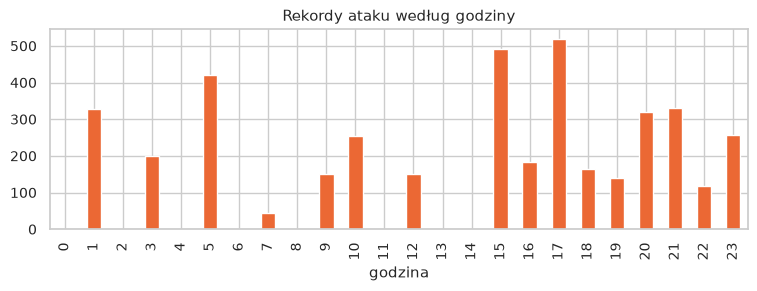

In [10]:
print('Rekordy attack=1 bez etykiety procesu:', attack_table['bez procesu'].sum(), 'w', (attack_table['bez procesu'] > 0).sum(), 'atakach')

hours = pd.DataFrame({
    'rekordy': test['time'].dt.hour.value_counts(),
    'rekordy ataku': attacks['time'].dt.hour.value_counts(),
}).sort_index().fillna(0)
hours['rekordy ataku'].plot(kind='bar', figsize=(9, 2.6), color='#eb6834')
plt.title('Rekordy ataku według godziny')
plt.xlabel('godzina')
plt.show()

> **Decyzja D7: jedyną etykietą jest `attack`**
> Etykiety `attack_P1`, `attack_P2`, `attack_P3` są niepełne, a jako cechy byłyby wprost przeciekiem odpowiedzi. Zostają tylko do opisu w EDA.
> **Przykład:** atak z 9.07 o 21:15 trwa 123 sekundy, a `attack_P1` obejmuje tylko 45 z nich. Łącznie 154 rekordy ataku nie mają etykiety procesu.

> **Decyzja D8: nie oceniamy modelu przez accuracy**
> Ataki to 2,5% rekordów, więc model, który nigdy nie alarmuje, ma accuracy 97,5% i jest bezużyteczny. Mierzymy ROC-AUC, PR-AUC, precision, recall, odsetek fałszywych alarmów oraz liczbę wykrytych ataków spośród 25. Ta ostatnia miara jest ważna, bo jeden atak to setki podobnych rekordów, a operatora interesuje, czy atak został zauważony.

> **Decyzja D9: `time` nie jest cechą**
> Ataki były wykonywane według harmonogramu eksperymentu, a test ma więcej godzin popołudniowych niż nocnych. Model nauczyłby się planu testów, a nie zachowania procesu.
> **Przykład:** w godzinach 2, 4, 6, 8, 11, 13, 14 i 0 nie ma ani jednego rekordu ataku.

## 5. Statystyki i rozkłady

W tabeli i na wykresach używamy kolumn zmiennych w train. Statystyki liczymy na ruchu normalnym z train1, bo to on definiuje, co jest normalne.

In [11]:
varying = [c for c in features if unique_train[c] > 1]
continuous = [c for c in varying if unique_train[c] > 10]
stats = train[varying].describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skośność'] = train[varying].skew()
print('Zmienne:', len(varying), ' ciągłe:', len(continuous))
print('Odchylenie standardowe: min', round(stats['std'].min(), 4), ' mediana', round(stats['std'].median(), 2), ' max', round(stats['std'].max(), 1))
stats.sort_values('std', ascending=False).round(3).head(10)

Zmienne: 57  ciągłe: 55
Odchylenie standardowe: min 0.0016  mediana 16.86  max 6823.3


,mean,std,min,50%,max,skośność
P3_LCV01D,7201.476,6823.292,-288.000,6416.000,18416.000,0.092
P3_LCP01D,4600.289,5117.358,-8.000,1944.000,13816.000,0.673
P3_LIT01,13576.485,4264.679,5123.000,14073.000,19539.000,-0.347
P4_ST_GOV,17847.172,1819.295,12625.000,17801.000,26398.000,0.371
P3_FIT01,1152.714,1781.401,-27.000,18.000,5415.000,1.161
P1_FT02Z,1820.165,1165.998,25.026,2623.177,2857.546,-0.525
P1_B400B,1820.188,1165.991,25.026,2623.554,2857.546,-0.525
P3_PIT01,652.258,1149.209,-24.000,-18.000,3871.000,1.643
P1_FT02,1153.605,877.698,4.807,1692.238,2006.569,-0.280
P1_FT01Z,885.553,72.284,0.000,907.013,1181.045,-2.915


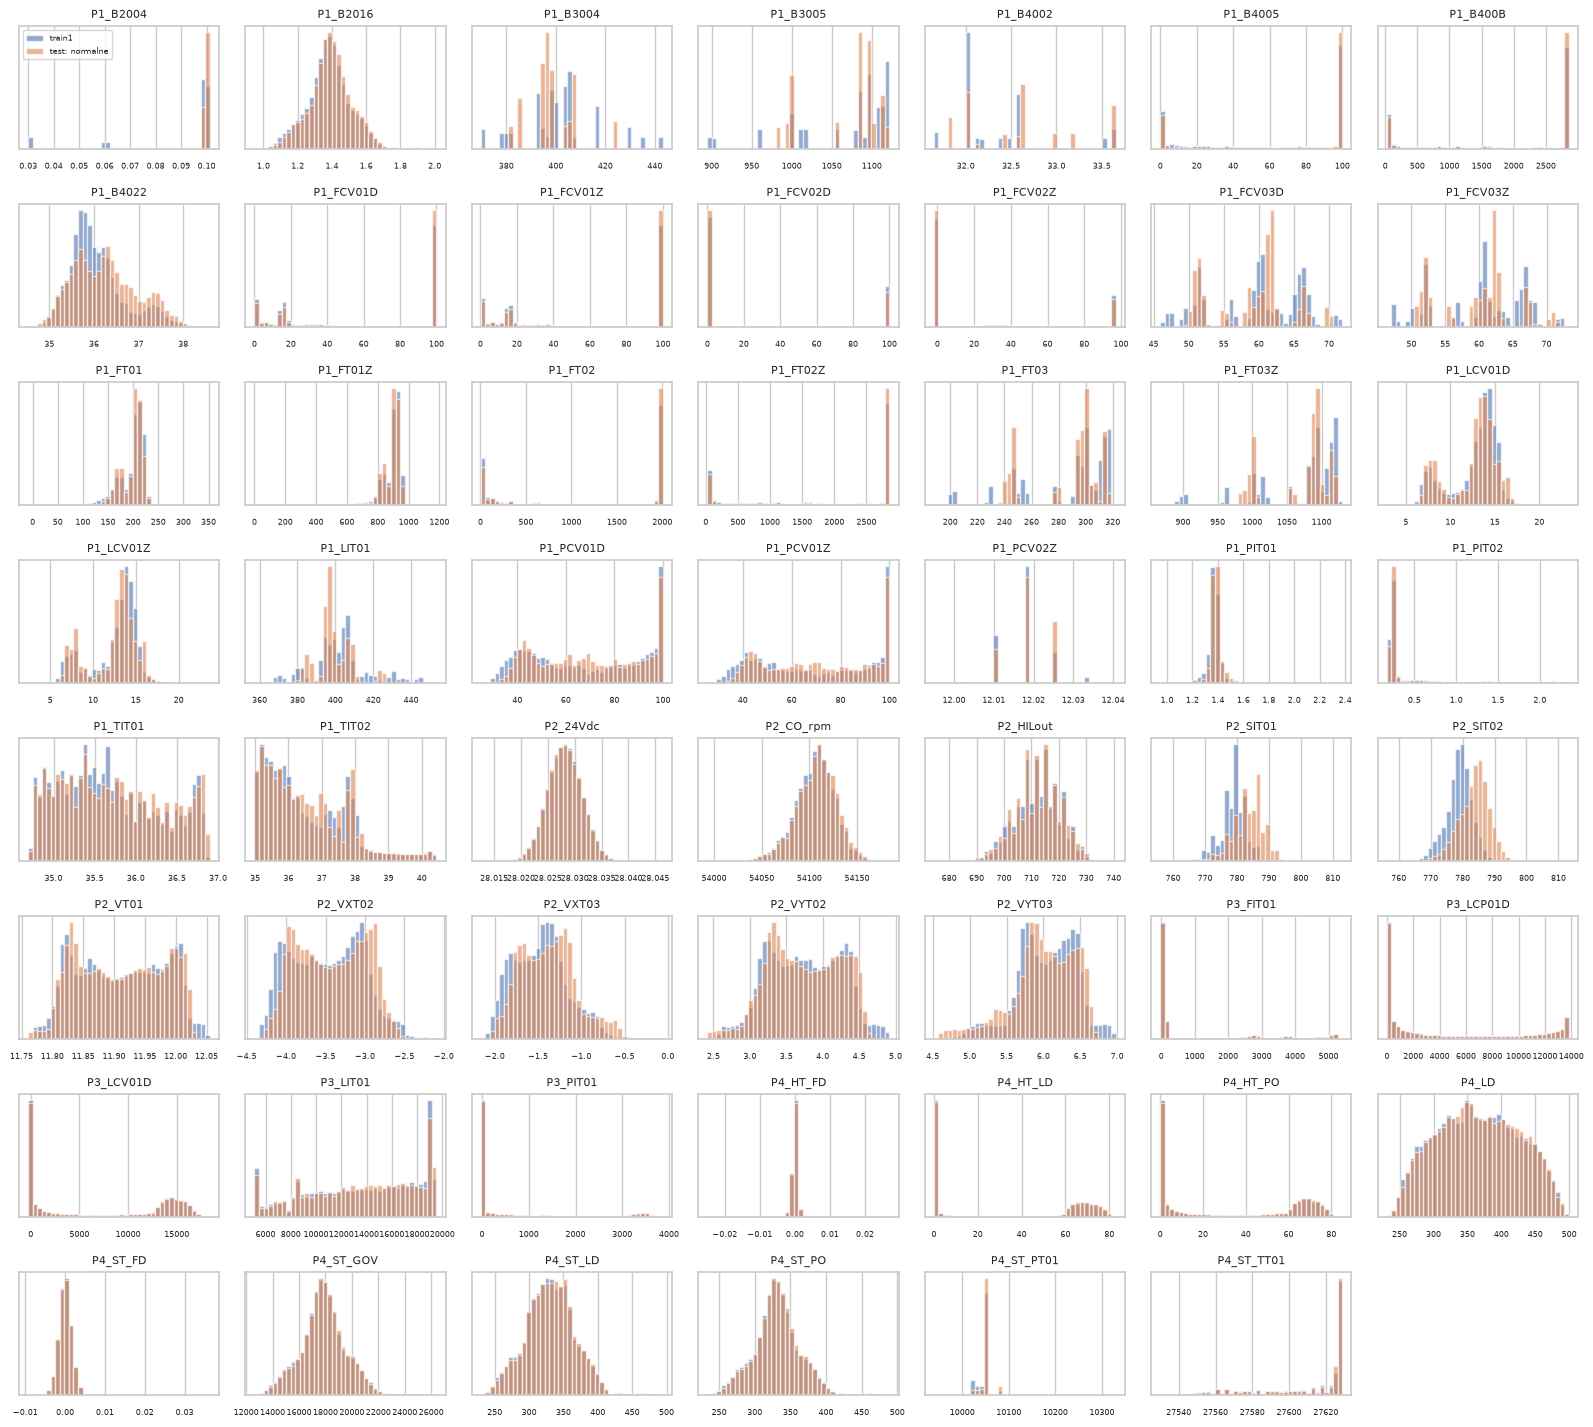

In [12]:
cols = 7
rows_n = int(np.ceil(len(continuous) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(16, rows_n * 1.8))
for ax, c in zip(axes.flat, continuous):
    bins = np.histogram_bin_edges(train[c], bins=40)
    ax.hist(train[c], bins=bins, density=True, alpha=0.6, label='train1')
    ax.hist(normal[c], bins=bins, density=True, alpha=0.6, label='test: normalne')
    ax.set_title(c, fontsize=8)
    ax.tick_params(labelsize=6)
    ax.set_yticks([])
for ax in axes.flat[len(continuous):]:
    ax.axis('off')
axes.flat[0].legend(fontsize=6)
plt.tight_layout()
plt.show()

Rozkłady są wielomodalne, a nie dzwonowe, bo instalacja pracuje w kilku stanach ustalonych. Oznacza to, że sama odległość od średniej (baseline) będzie słabym detektorem: środek rozkładu często leży między trybami pracy.

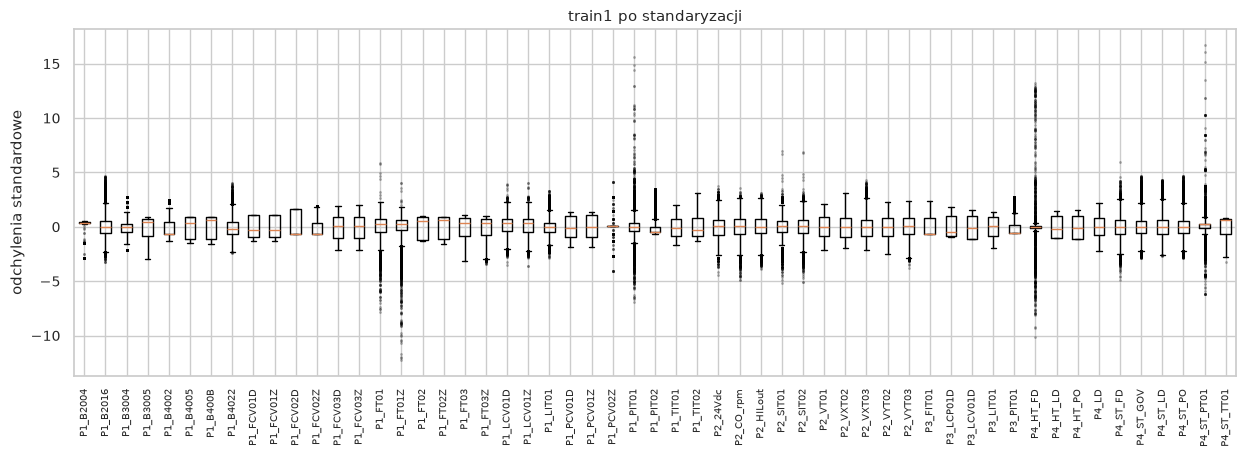

Udział rekordów z |z| > 5:
P4_HT_FD      0.0082
P1_FT01Z      0.0036
P1_PIT01      0.0032
P4_ST_PT01    0.0028
P1_FT01       0.0012


In [13]:
scaled = (train[continuous] - train[continuous].mean()) / train[continuous].std()
plt.figure(figsize=(15, 4.5))
plt.boxplot(scaled.sample(20000, random_state=42).to_numpy(), tick_labels=continuous, flierprops={'markersize': 1, 'alpha': 0.3})
plt.xticks(rotation=90, fontsize=7)
plt.ylabel('odchylenia standardowe')
plt.title('train1 po standaryzacji')
plt.show()

outliers = (scaled.abs() > 5).mean().sort_values(ascending=False)
print('Udział rekordów z |z| > 5:')
print(outliers.head(5).round(4).to_string())

> **Decyzja D10: nie usuwamy wartości odstających**
> Plik train nie zawiera ataków, więc jego skrajne wartości to prawdziwe, rzadkie stany instalacji. Ich usunięcie zawęziłoby pojęcie normalności i zwiększyło liczbę fałszywych alarmów. W plikach test wartości odstające to z kolei dokładnie to, czego szukamy.
> **Przykład:** `P4_HT_FD` ma 0,8% rekordów powyżej 5 odchyleń, a są to zwykłe wahania częstotliwości.

Zmienne mają bardzo różną skalę: odchylenie od 0,0016 do 6823. Standaryzacja będzie potrzebna dla baseline, choć Isolation Forest jej nie wymaga, bo dzieli każdą cechę osobno. Sprawdzamy jedną podejrzaną kolumnę.

In [14]:
print('P1_PCV02Z, odchylenie w train:', round(train['P1_PCV02Z'].std(), 4))
print('test1, pierwsze 35 min:', test1['P1_PCV02Z'].iloc[:2100].round(2).value_counts().head(2).to_dict())
print('test1, później:        ', test1['P1_PCV02Z'].iloc[2400:].round(2).value_counts().head(2).to_dict())
shift = (test1['P1_PCV02Z'].iloc[:2100].mean() - train['P1_PCV02Z'].mean()) / train['P1_PCV02Z'].std()
print('Różnica po standaryzacji:', round(shift, 1), 'odchyleń')

P1_PCV02Z, odchylenie w train: 0.0056
test1, pierwsze 35 min: {12.26: 1123, 12.25: 960}
test1, później:         {12.02: 19170, 12.01: 14594}
Różnica po standaryzacji: 43.1 odchyleń


> **Decyzja D11: zostawiamy `P1_PCV02Z`, a w baseline obcinamy wartości standaryzowane**
> Ta kolumna ma w train bardzo małe odchylenie (0,0056), więc drobna różnica wygląda po standaryzacji jak wielka anomalia, choć fizycznie to tylko 0,24 punktu procentowego otwarcia zaworu.
> **Przykład:** na początku test1 zawór stoi na 12,26 zamiast 12,02. To ponad 40 odchyleń, a rekordy są normalne. Isolation Forest sobie z tym radzi (test w etapie 9 sprawdza alarmy z tego fragmentu), ale baseline z z-score wymaga obcięcia, np. do ±10.

## 6. Zmienne kategoryczne

Prawdziwych zmiennych kategorycznych jest tu mało. Są to etykiety, proces będący celem ataku oraz wartości zadane mocy.

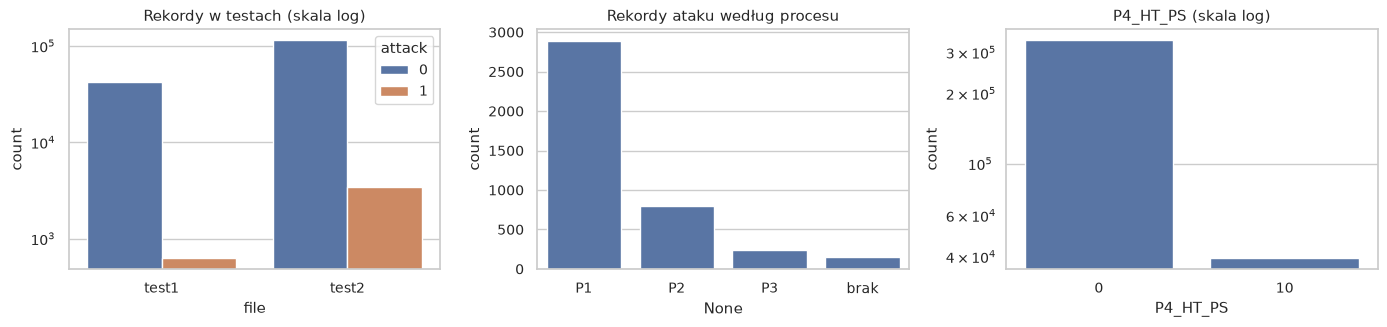

P4_ST_PS      0      50
P4_HT_PS               
0         197623      0
10             0  18377
P4_ST_PS      0      50
P4_HT_PS               
0         140936      0
10             0  21066


In [15]:
process = attacks[labels[1:]].idxmax(axis=1).str.replace('attack_', '')
process = process.where(attacks[labels[1:]].sum(axis=1) > 0, 'brak')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
sns.countplot(data=test, x='file', hue='attack', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Rekordy w testach (skala log)')
sns.countplot(x=process, order=['P1', 'P2', 'P3', 'brak'], ax=axes[1])
axes[1].set_title('Rekordy ataku według procesu')
sns.countplot(x=pd.concat([train['P4_HT_PS'], test['P4_HT_PS']]).astype(str), ax=axes[2])
axes[2].set_yscale('log')
axes[2].set_title('P4_HT_PS (skala log)')
plt.tight_layout()
plt.show()

print(pd.crosstab(train['P4_HT_PS'], train['P4_ST_PS']))
print(pd.crosstab(test['P4_HT_PS'], test['P4_ST_PS']))

Ataki dotyczą głównie procesu P1. Na P3 są tylko 2 ataki i oba w test2, więc walidacja (test1) nie zawiera żadnego ataku na P3. Próg dobieramy jednak po fałszywych alarmach na rekordach normalnych, więc to nie przeszkadza.

`P4_HT_PS` i `P4_ST_PS` to zaplanowana moc dwóch modeli i zawsze zmieniają się razem: 0 odpowiada 0, a 10 odpowiada 50.

> **Decyzja D13: usuwamy `P4_ST_PS`**
> To dokładna kopia informacji z `P4_HT_PS`. Odwzorowanie 1:1 zachodzi w każdym rekordzie train i test, także podczas ataków, więc nic nie tracimy. To jedyna kolumna, którą usuwamy z powodu nadmiarowości (dlaczego nie inne, pokazuje etap 7).

## 7. Korelacje

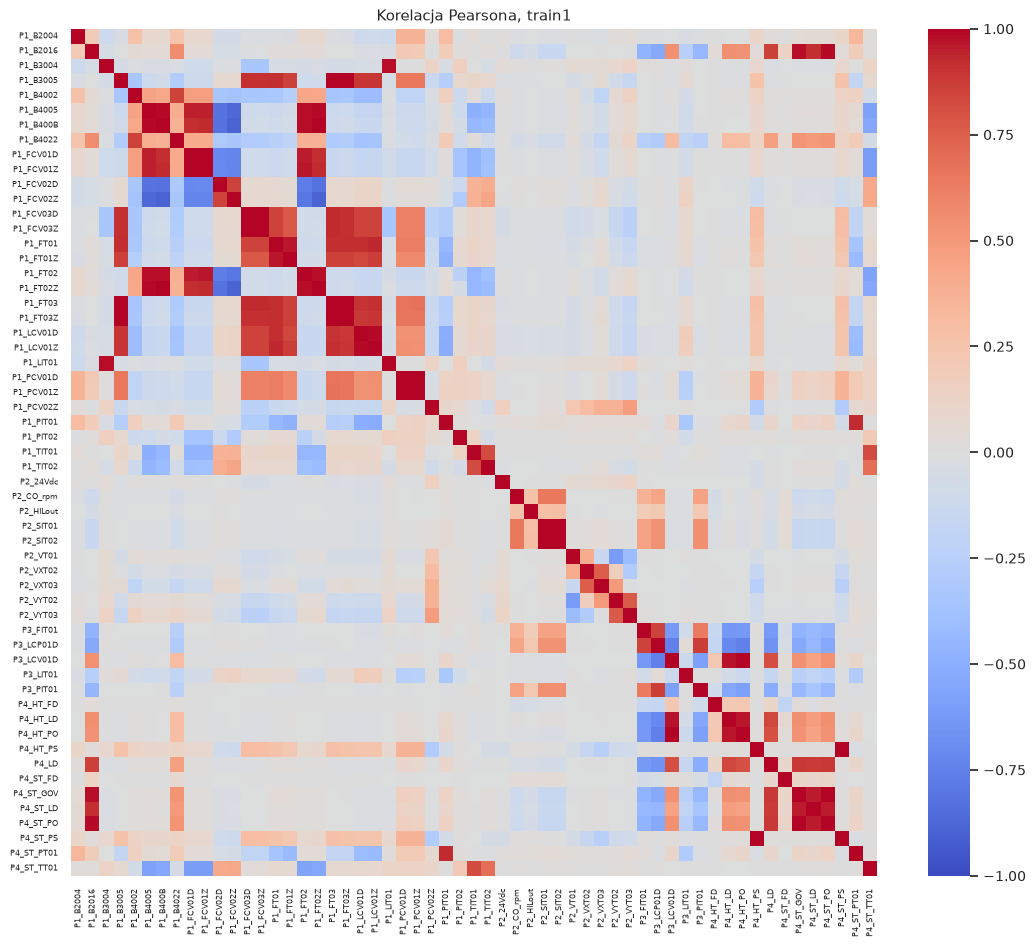

Pary |r| > 0.99: 13  |r| > 0.95: 27


P4_HT_PS   P4_ST_PS     1.0000
P1_B400B   P1_FT02Z     0.9999
P4_ST_GOV  P4_ST_PO     0.9997
P1_FCV01D  P1_FCV01Z    0.9995
P1_PCV01D  P1_PCV01Z    0.9994
P3_LCV01D  P4_HT_PO     0.9990
P1_B3005   P1_FT03Z     0.9978
P2_SIT01   P2_SIT02     0.9974
dtype: float64

In [16]:
corr = train[varying].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.title('Korelacja Pearsona, train1')
plt.show()

pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print('Pary |r| > 0.99:', (pairs > 0.99).sum(), ' |r| > 0.95:', (pairs > 0.95).sum())
pairs.head(8).round(4)

13 par ma korelację powyżej 0,99. Zwykle usuwa się wtedy jedną z kolumn. Tutaj najpierw sprawdzamy, czy ta zależność utrzymuje się podczas ataku, bo atakujący może podać fałszywą wartość tylko jednej z dwóch powiązanych zmiennych.

In [17]:
rows = []
for a, b in [('P1_FCV01D', 'P1_FCV01Z'), ('P1_FCV03D', 'P1_FCV03Z'), ('P1_PCV01D', 'P1_PCV01Z'), ('P1_LCV01D', 'P1_LCV01Z')]:
    diff = train[a] - train[b]
    z_normal = ((normal[a] - normal[b] - diff.mean()) / diff.std()).abs()
    z_attack = ((attacks[a] - attacks[b] - diff.mean()) / diff.std()).abs()
    rows.append({
        'para': a + ' / ' + b,
        'r w train': round(train[a].corr(train[b]), 4),
        'normalne: |z|>5': round((z_normal > 5).mean(), 4),
        'atak: |z|>5': round((z_attack > 5).mean(), 4),
        'normalne: p99': round(z_normal.quantile(0.99), 1),
        'atak: p99': round(z_attack.quantile(0.99), 1),
    })
pd.DataFrame(rows)

,para,r w train,normalne: |z|>5,atak: |z|>5,normalne: p99,atak: p99
0,P1_FCV01D / P1_FCV01Z,0.9995,0.0008,0.0020,3.7,4.0
1,P1_FCV03D / P1_FCV03Z,0.9973,0.0001,0.0483,2.1,35.6
2,P1_PCV01D / P1_PCV01Z,0.9994,0.0001,0.0088,2.1,4.9
3,P1_LCV01D / P1_LCV01Z,0.9853,0.0005,0.0831,2.2,11.1


> **Decyzja D12: nie usuwamy kolumn skorelowanych, a różnice `D − Z` dodajemy jako cechy w etapie 3**
> W zwykłym zadaniu ML druga kolumna z pary jest zbędna. W OT rozjazd między poleceniem a rzeczywistym położeniem zaworu to właśnie objaw ataku, więc usunięcie jednej kolumny skasowałoby ten sygnał.
> **Przykład:** `P1_FCV03D` i `P1_FCV03Z` mają r = 0,997. Różnica przekracza 5 odchyleń w 0,01% rekordów normalnych i w 4,8% rekordów ataku, a dla `P1_LCV01` w 0,05% i 8,3%.

## 8. Pary zmiennych

P1_B2004      0.261
P1_LCV01D     0.256
P1_LCV01Z     0.249
P1_PIT01      0.224
P4_ST_PT01    0.220
P1_FCV02Z     0.209
P1_FT01       0.204
P1_FT01Z      0.203


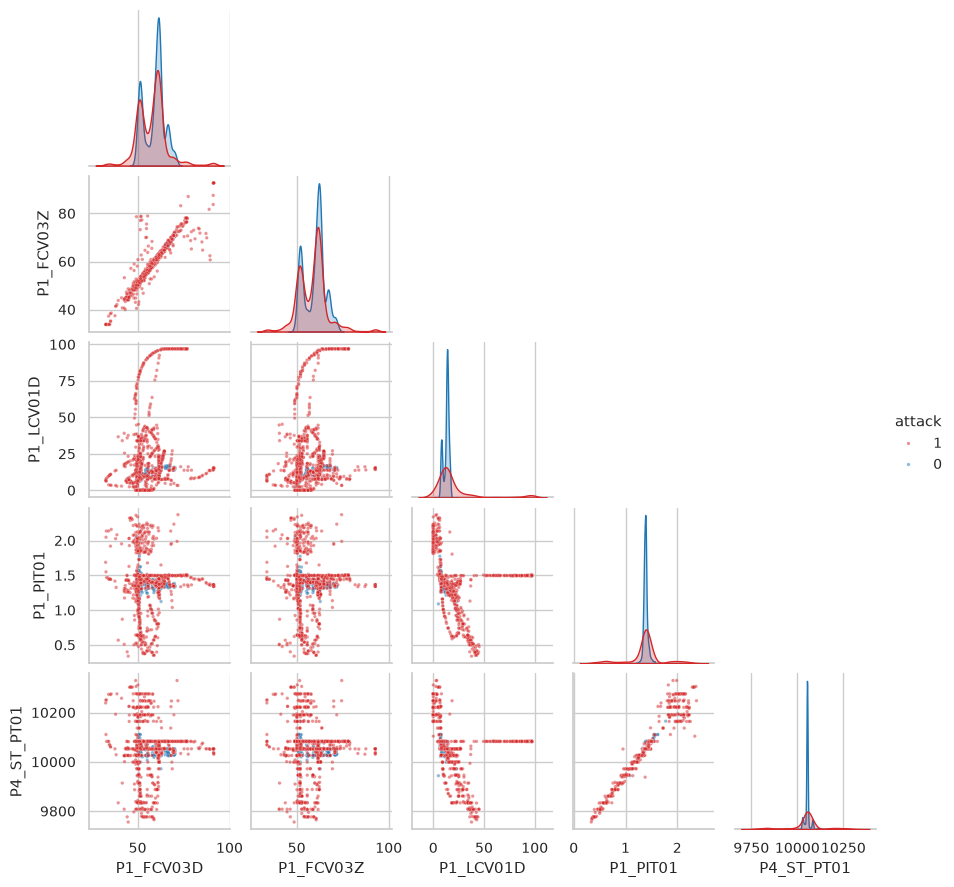

In [18]:
test_ks = pd.Series({c: ks_2samp(normal[c].sample(20000, random_state=0), attacks[c].sample(4000, random_state=0)).statistic for c in continuous}).sort_values(ascending=False)
print(test_ks.head(8).round(3).to_string())

pair_columns = ['P1_FCV03D', 'P1_FCV03Z', 'P1_LCV01D', 'P1_PIT01', 'P4_ST_PT01']
sample = pd.concat([test[test['attack'] == v].sample(1500, random_state=42) for v in (0, 1)])
sns.pairplot(sample[pair_columns + ['attack']], hue='attack', hue_order=[1, 0], palette={0: 'tab:blue', 1: 'tab:red'},
             corner=True, height=1.8, plot_kws={'s': 6, 'alpha': 0.5})
plt.show()

> **Decyzja D14: pairplot tylko dla 5 zmiennych i po 1500 rekordów z każdej klasy**
> Pełny pairplot dla 56 zmiennych to 1540 wykresów, których nie da się przeczytać. Wybrałem zmienne, które statystyka Kołmogorowa-Smirnowa wskazuje jako najbardziej różniące ataki od normy, plus parę `FCV03` do pokazania rozjazdu `D − Z`. Równe próbki są potrzebne, bo przy proporcji 2,5% ataki zniknęłyby na wykresie.
> Próbka służy tylko rysowaniu i nie wpływa na żadne obliczenia.

Punkty ataku często układają się poza główną chmurą, ale mocno na nią zachodzą. Pojedynczy rekord ataku często wygląda normalnie, co widać też w teście poniżej.

## 9. Czy jeden plik treningowy wystarczy?

Zbiór ma trzy pliki treningowe. Plik train1 obejmuje 60 z 352 godzin normalnej pracy. Sprawdzamy dwie rzeczy: czy rekordy normalne z testu mieszczą się w zakresie train i czy więcej danych pomaga prostemu detektorowi.

To tylko test decyzji o danych, a nie ostateczny model z etapu 4.

In [19]:
out = ((normal[features] < train[features].min()) | (normal[features] > train[features].max())).mean().sort_values(ascending=False)
print('Normalne z testu poza zakresem train:')
print(out.head(4).round(3).to_string())

c = 'P1_B2004'
over = np.maximum(normal[c] - train[c].max(), train[c].min() - normal[c])
print(f'\n{c}: przekroczenie zakresu to mediana {over[over > 0].median() / train[c].std():.3f} odchylenia')

drift = pd.Series({c: ks_2samp(train[c].sample(20000, random_state=0), normal[c].sample(20000, random_state=0)).statistic for c in continuous}).sort_values(ascending=False)
print('\nNajwiększa różnica train / normalne z testu (KS):')
print(drift.head(4).round(3).to_string())
print(f"\nP2_SIT01: średnia train {train['P2_SIT01'].mean():.0f}, test {normal['P2_SIT01'].mean():.0f} obr./min")

Normalne z testu poza zakresem train:
P1_B2004     0.172
P1_B4002     0.072
P1_PCV02Z    0.013
P3_PIT01     0.009

P1_B2004: przekroczenie zakresu to mediana 0.020 odchylenia



Największa różnica train / normalne z testu (KS):
P2_SIT02    0.475
P2_SIT01    0.473
P1_B2004    0.467
P1_B4002    0.423

P2_SIT01: średnia train 779, test 783 obr./min


In [20]:
url = 'https://raw.githubusercontent.com/icsdataset/hai/master/hai-21.03/'
train2 = pd.read_csv(url + 'train2.csv.gz')
train3 = pd.read_csv(url + 'train3.csv.gz')

model_columns = [c for c in features if train[c].nunique() > 1]
y = test['attack'].to_numpy()
rows = []
for name, base_data in [('train1', train), ('train1+2', pd.concat([train, train2])), ('train1+3', pd.concat([train, train3])), ('train1+2+3', pd.concat([train, train2, train3]))]:
    result = []
    for seed in range(5):
        model = IsolationForest(n_estimators=200, max_samples=256, random_state=seed, n_jobs=-1).fit(base_data[model_columns].to_numpy())
        score = -model.score_samples(test[model_columns].to_numpy())
        threshold = np.quantile(-model.score_samples(base_data[model_columns].sample(50000, random_state=seed).to_numpy()), 0.99)
        alarm = score > threshold
        result.append([roc_auc_score(y, score), average_precision_score(y, score), alarm[y == 0].mean(), alarm[y == 1].mean(), sum(alarm[s:e + 1].any() for s, e in all_episodes)])
    mean, std = np.mean(result, axis=0), np.std(result, axis=0)
    rows.append({'dane': name, 'wiersze': len(base_data), 'ROC-AUC': round(mean[0], 3), '± std': round(std[0], 3), 'PR-AUC': round(mean[1], 3), 'FPR': round(mean[2], 3), 'recall': round(mean[3], 3), 'ataki z 25': round(mean[4], 1)})
pd.DataFrame(rows)

,dane,wiersze,ROC-AUC,± std,PR-AUC,FPR,recall,ataki z 25
0,train1,216000,0.711,0.008,0.074,0.009,0.059,9.6
1,train1+2,442801,0.694,0.011,0.049,0.010,0.024,6.8
2,train1+3,694801,0.710,0.008,0.091,0.004,0.043,7.8
3,train1+2+3,921602,0.729,0.005,0.085,0.006,0.057,10.8


In [21]:
model = IsolationForest(n_estimators=200, max_samples=256, random_state=0, n_jobs=-1).fit(train[model_columns].to_numpy())
score = -model.score_samples(test[model_columns].to_numpy())
threshold = np.quantile(-model.score_samples(train[model_columns].sample(50000, random_state=0).to_numpy()), 0.99)
print('Alarmy w pierwszych 35 min test1 (P1_PCV02Z = 12,26):', round((score[:2100] > threshold).mean(), 4))
print('Alarmy w pozostałych rekordach normalnych:', round((score > threshold)[y == 0].mean(), 4))

Alarmy w pierwszych 35 min test1 (P1_PCV02Z = 12,26): 0.0
Alarmy w pozostałych rekordach normalnych: 0.0136


> **Decyzja D2: używamy tylko train1, test1 i test2**
> Czterokrotnie więcej danych podnosi ROC-AUC tylko o około 0,02, daje około 1 wykryty atak więcej i nie poprawia recall. Mniejsze pliki oznaczają szybszą pracę, a spakowane dane to około 53 MB zamiast około 150 MB.
> **Przykład:** `P1_B2004` wygląda groźnie, bo 17% normalnych rekordów z testu wykracza poza zakres train, ale przekroczenie to 0,02 odchylenia. Podobnie `P2_SIT01` ma duży wynik KS, a różnica to około 4 obroty przy średniej 780. Duża różnica statystyczna nie oznacza tu dużej różnicy fizycznej.
> Jeśli w etapie 4 model będzie miał za dużo fałszywych alarmów, łatwo dodać pozostałe pliki.

**Najważniejszy wniosek z tej tabeli:** ROC-AUC około 0,71 i wykrycie mniej więcej 10 z 25 ataków to słaby wynik. Isolation Forest na pojedynczych rekordach nie widzi zmian w czasie, a wiele ataków w HAI to subtelne zmiany, które mieszczą się w normalnym zakresie wartości.

> **Decyzja D16: w etapie 3 dodajemy cechy czasowe**
> Dane to szereg czasowy, a model traktuje każdą sekundę osobno. Różnice `D − Z` (D12) oraz statystyki z krótkich okien, np. średnia i zmiana z 60 sekund, dają modelowi informację o przebiegu w czasie, nadal bez zmiany modelu na bardziej złożony.

## 10. Co dzieje się po zakończeniu ataku

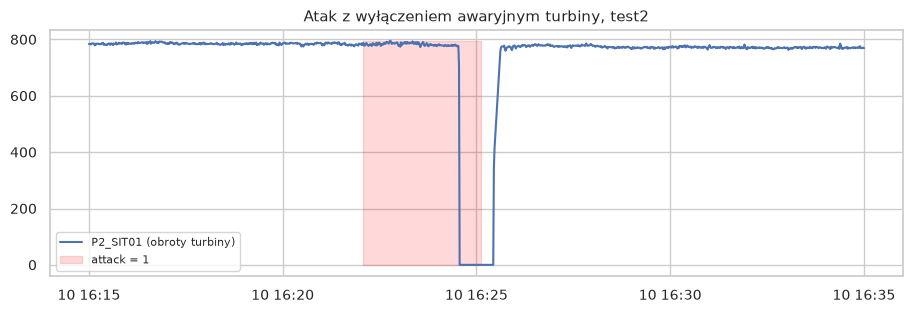

,size,mean
atak,4078,1.116
do 1 min po,1500,0.976
1-5 min po,6000,0.782
5-30 min po,36924,0.768
ponad 30 min po,111389,0.809


In [22]:
example = test[(test['file'] == 'test2') & test['time'].between('2020-07-10 16:15:00', '2020-07-10 16:35:00')]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(example['time'], example['P2_SIT01'], label='P2_SIT01 (obroty turbiny)')
ax.fill_between(example['time'], 0, example['P2_SIT01'].max(), where=example['attack'] == 1, color='red', alpha=0.15, label='attack = 1')
ax.legend(fontsize=8, loc='lower left')
ax.set_title('Atak z wyłączeniem awaryjnym turbiny, test2')
plt.show()

a = test['attack'].to_numpy()
since = np.empty(len(a))
count = np.inf
for i, value in enumerate(a):
    count = 0 if value == 1 else count + 1
    since[i] = count

mean, std = train[varying].mean(), train[varying].std()
distance = ((test[varying] - mean) / std).abs().clip(upper=10).mean(axis=1)
groups = pd.cut(since, [-1, 0, 60, 300, 1800, 1e9], labels=['atak', 'do 1 min po', '1-5 min po', '5-30 min po', 'ponad 30 min po'])
distance.groupby(groups, observed=True).agg(['size', 'mean']).round(3)

Etykieta `attack` kończy się wcześniej niż skutek ataku. Na wykresie turbina stoi jeszcze po zakończeniu etykiety. Przez pierwszą minutę po ataku rekordy są wyraźnie dalej od normy, a później wracają do poziomu ruchu normalnego.

> **Decyzja D15: nie zmieniamy etykiet, ale fałszywe alarmy liczymy też bez 60 sekund po ataku**
> Etykiety to dane źródłowe i ich ręczna poprawa byłaby dopasowywaniem danych pod wynik. Model nie powinien jednak być karany za alarm w chwili, gdy instalacja realnie wraca do normy.
> **Przykład:** 10.07 o 16:24:33 włącza się `P2_Emerg` i trwa 47 sekund, ale tylko 35 z nich ma etykietę ataku. W całym teście rekordów do 60 sekund po ataku jest 1500 (około 1% normalnych), więc FPR podajemy w dwóch wariantach.

## 11. Podsumowanie decyzji

Po decyzjach zostaje 56 cech: 79 − 19 stałych − 3 stałe w train − `P4_ST_PS`.

| # | Decyzja | Dlaczego | Przykład z danych |
|---|---|---|---|
| D1 | HAI 21.03 zamiast CIC-IDS2017 | projekt dotyczy OT, a CIC-IDS2017 to ruch biurowy; HAI ma realne PLC i publiczny dostęp | pliki train mają 0 rekordów ataku |
| D2 | tylko train1, test1, test2 | 4 razy więcej danych to tylko około +0,02 ROC-AUC i bez poprawy recall | `P1_B2004`: 17% poza zakresem, ale o 0,02 odchylenia |
| D3 | podział po plikach, nie losowy | sąsiednie sekundy są prawie identyczne, więc losowy podział zawyżyłby wynik | autokorelacja 0,999 po 1 s |
| D4 | usunięcie 1. wiersza train1 | ten sam pomiar jest w train i test | 11.07 00:00:00, 79 z 79 wartości zgodnych |
| D5 | usunięcie 19 kolumn stałych | jedna wartość nie niesie informacji | `P1_PP02D` zawsze równe 1 |
| D6 | 3 kolumny stałe w train poza modelem, jako reguła | model ich nie nauczy się, ale sygnał jest silny | `P1_PCV02D` ≠ 12: 185 rekordów, wszystkie atak |
| D7 | tylko etykieta `attack` | `attack_P*` są niepełne i byłyby przeciekiem | 154 rekordy ataku bez procesu |
| D8 | bez accuracy, liczymy też wykryte ataki | ataki to 2,5% rekordów | brak alarmów daje 97,5% accuracy |
| D9 | `time` nie jest cechą | model nauczyłby się harmonogramu testów | w godzinach 0, 2, 4, 6, 8, 11, 13, 14 brak ataków |
| D10 | zostawiamy wartości odstające | w train to prawdziwe stany instalacji | `P4_HT_FD`: 0,8% rekordów powyżej 5 odchyleń |
| D11 | zostawiamy `P1_PCV02Z`, obcinamy z-score w baseline | małe odchylenie sztucznie powiększa różnice | 12,26 zamiast 12,02 to ponad 40 odchyleń |
| D12 | nie usuwamy skorelowanych, dodajemy `D − Z` | rozjazd polecenia i położenia to objaw ataku | `FCV03`: 0,01% rekordów normalnych, 4,8% ataku |
| D13 | usuwamy `P4_ST_PS` | dokładna kopia `P4_HT_PS` także podczas ataków | 0→0, 10→50 w każdym rekordzie |
| D14 | pairplot: 5 zmiennych, po 1500 rekordów na klasę | 56 zmiennych to 1540 wykresów, a ataki by zniknęły | wybór według statystyki KS |
| D15 | etykiety bez zmian, FPR także bez 60 s po ataku | skutek ataku trwa dłużej niż etykieta | turbina stoi po końcu etykiety, 16:25 |
| D16 | cechy czasowe w etapie 3 | model widzi tylko pojedyncze sekundy | test: około 10 z 25 wykrytych ataków |

## Dalsze kroki (etap 3)
1. Usunąć kolumny i wiersz według D4, D5, D6, D13.
2. Podzielić dane: train1, walidacja test1, test test2 (D3).
3. Dodać różnice `D − Z` i cechy z okien czasowych (D12, D16).
4. Dopasować skalowanie tylko na train.